# Multinomial Logistic Regression (Softmax Regression) on the Iris Dataset

This notebook builds a **multiclass classifier** for the three Iris species and explains the complete prediction process:

$$
\text{input features}
\rightarrow \text{class logits}
\rightarrow \text{Softmax probabilities}
\rightarrow \operatorname{argmax}
\rightarrow \text{predicted class}
$$

## Learning Objectives

By the end of this notebook, you will be able to:

- prepare a dataset for multiclass classification;
- train a **Multinomial Logistic Regression** model;
- interpret the learned weights and biases;
- calculate logits and Softmax probabilities manually;
- evaluate predictions with accuracy, cross-entropy, a classification report, and a confusion matrix;
- visualize multiclass decision regions; and
- compare a two-feature visualization model with a model that uses all four Iris features.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

sns.set_theme(style="whitegrid")

## 1. Load and Explore the Iris Dataset

The Iris dataset contains **150 flower samples**, four numerical input features, and three mutually exclusive species. Each species is one possible class.

In [2]:
raw_df = sns.load_dataset("iris")
raw_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(f"Dataset shape: {raw_df.shape}")
print(f"Duplicate rows: {raw_df.duplicated().sum()}")
print("\nMissing values per column:")
display(raw_df.isna().sum().to_frame("missing_values"))

print("Class distribution:")
display(raw_df["species"].value_counts().sort_index().to_frame("samples"))

print("Numerical summary:")
display(raw_df.describe().round(2))

Dataset shape: (150, 5)
Duplicate rows: 1

Missing values per column:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


Class distribution:


,samples
species,
setosa,50
versicolor,50
virginica,50


Numerical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. Encode the Target Classes

`LabelEncoder` converts the species names into **integer class labels**. Scikit-learn can also train directly with string labels, but integer labels make the class indices easier to connect to the mathematical notation.

| Species | Label-encoded target | Equivalent one-hot target |
|---|---:|---|
| Setosa | `0` | `[1, 0, 0]` |
| Versicolor | `1` | `[0, 1, 0]` |
| Virginica | `2` | `[0, 0, 1]` |

The notebook uses **label encoding**, not one-hot encoding. Both representations identify the same correct class; for example, label `1` and one-hot vector `[0, 1, 0]` both mean **Versicolor**.

Scikit-learn's `LogisticRegression.fit()` expects the target `y` as a **one-dimensional vector of class labels**, so `0`, `1`, and `2` are sufficient. Internally, the multinomial loss selects the predicted probability for the correct class, which is mathematically equivalent to using a one-hot target in the categorical cross-entropy formula. We may construct one-hot targets to demonstrate that formula, but we should not pass a one-hot target matrix to this `LogisticRegression` model because it can represent a different multi-output or multilabel problem.

> [!NOTE]
> The integer labels do **not** create an order between the species. The values `0`, `1`, and `2` are identifiers only; class `2` is not greater or more important than class `1`.

In [4]:
encoder = LabelEncoder()
df = raw_df.copy()
df["species"] = encoder.fit_transform(df["species"])

class_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print("Class mapping:", class_mapping)
df.head()

Class mapping: {'setosa': np.int64(0), 'versicolor': np.int64(1), 'virginica': np.int64(2)}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Select and Visualize Two Features

The first model uses only **sepal length** and **petal length** so that its decision regions can be plotted in two dimensions. A later model uses all four features.

- $X$ contains the input features.
- $y$ contains the encoded target class.

In [5]:
feature_names = ["sepal_length", "petal_length"]
X = df[feature_names]
y = df["species"]

selected_data = df[feature_names + ["species"]]
selected_data.head()

,sepal_length,petal_length,species
0,5.1,1.4,0
1,4.9,1.4,0
2,4.7,1.3,0
3,4.6,1.5,0
4,5.0,1.4,0


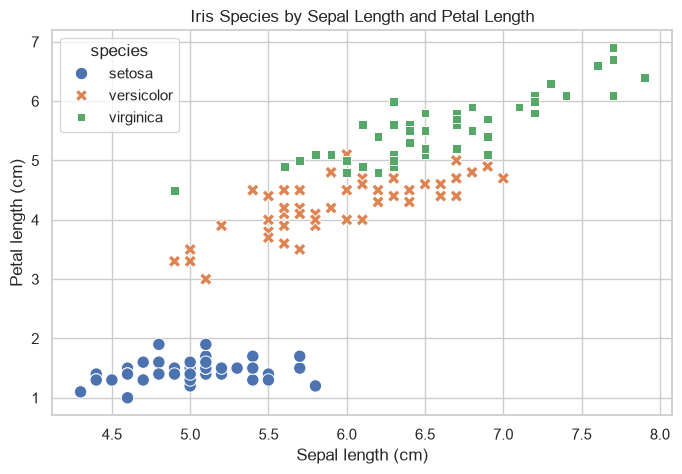

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=raw_df,
    x="sepal_length",
    y="petal_length",
    hue="species",
    style="species",
    s=80,
)
plt.title("Iris Species by Sepal Length and Petal Length")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal length (cm)")
plt.show()

## 4. Create Stratified Training and Test Sets

- `test_size=0.2` reserves 20% of the data for evaluation.
- `random_state=2` makes the split reproducible.
- `stratify=y` preserves the class proportions in both subsets.

The test data must remain unseen during training so that it measures how well the model generalizes.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2,
    stratify=y,
)

split_summary = pd.DataFrame(
    {
        "training_samples": y_train.value_counts().sort_index(),
        "test_samples": y_test.value_counts().sort_index(),
    }
).rename(index=dict(enumerate(encoder.classes_)))

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
display(split_summary)

X_train shape: (120, 2)
X_test shape: (30, 2)


,training_samples,test_samples
species,,
setosa,40,10
versicolor,40,10
virginica,40,10


## 5. Train the Multinomial Logistic Regression Model

`lbfgs` optimizes the model's categorical cross-entropy objective. With three classes, current scikit-learn versions fit the full multinomial model automatically.

For every class $k$, the model learns a weight vector $\mathbf{w}_k$ and bias $b_k$:

$$
z_k = \mathbf{w}_k^\top\mathbf{x} + b_k
$$

`LogisticRegression` also applies L2 regularization by default. Its `C` parameter controls the inverse regularization strength.

In [8]:
softmax_model = LogisticRegression(solver="lbfgs", max_iter=500)
softmax_model.fit(X_train, y_train)

softmax_classes = encoder.inverse_transform(softmax_model.classes_)
print("Encoded classes:", softmax_model.classes_)
print("Species order:", softmax_classes)

Encoded classes: [0 1 2]
Species order: ['setosa' 'versicolor' 'virginica']


In [9]:
weights = pd.DataFrame(
    softmax_model.coef_,
    index=softmax_classes,
    columns=feature_names,
)
biases = pd.Series(
    softmax_model.intercept_,
    index=softmax_classes,
    name="bias",
)

print("Weight matrix shape:", softmax_model.coef_.shape)
display(weights.round(4))
display(biases.round(4).to_frame())

Weight matrix shape: (3, 2)


,sepal_length,petal_length
setosa,-0.2861,-2.9121
versicolor,0.4268,-0.3589
virginica,-0.1408,3.2710


,bias
setosa,11.8414
versicolor,1.1550
virginica,-12.9964


## 6. Follow One Prediction Step by Step

For one sample, the complete model calculation is:

1. Calculate the class logits: $\mathbf{z}=W\mathbf{x}+\mathbf{b}$.
2. Convert the logits into probabilities with Softmax:

$$
p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}
$$

3. Select the class with the highest probability: $\hat{y}=\operatorname{argmax}_k p_k$.

The implementation below subtracts the largest logit before exponentiation. This does not change the probabilities and prevents numerical overflow.

In [10]:
def softmax(logits):
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)
    exponentials = np.exp(shifted_logits)
    return exponentials / np.sum(exponentials, axis=1, keepdims=True)


sample = X_test.iloc[[0]]
logits_manual = sample.to_numpy() @ softmax_model.coef_.T + softmax_model.intercept_
logits_sklearn = softmax_model.decision_function(sample)

probabilities_manual = softmax(logits_manual)
probabilities_sklearn = softmax_model.predict_proba(sample)

calculation = pd.DataFrame(
    {
        "logit_manual": logits_manual[0],
        "logit_sklearn": logits_sklearn[0],
        "probability_manual": probabilities_manual[0],
        "probability_sklearn": probabilities_sklearn[0],
    },
    index=softmax_classes,
)

predicted_position = np.argmax(probabilities_manual, axis=1)
predicted_code = softmax_model.classes_[predicted_position]
predicted_species = encoder.inverse_transform(predicted_code)
actual_species = encoder.inverse_transform(y_test.iloc[[0]].to_numpy())

display(sample)
display(calculation.round(6))
print("Probabilities sum to:", probabilities_manual.sum(axis=1))
print("Manual and scikit-learn logits match:", np.allclose(logits_manual, logits_sklearn))
print("Manual and scikit-learn probabilities match:", np.allclose(probabilities_manual, probabilities_sklearn))
print("Predicted species:", predicted_species[0])
print("Actual species:", actual_species[0])

,sepal_length,petal_length
45,4.8,1.4


,logit_manual,logit_sklearn,probability_manual,probability_sklearn
setosa,6.391468,6.391468,0.975641,0.975641
versicolor,2.701288,2.701288,0.024359,0.024359
virginica,-9.092755,-9.092755,0.000000,0.000000


Probabilities sum to: [1.]
Manual and scikit-learn logits match: True
Manual and scikit-learn probabilities match: True
Predicted species: setosa
Actual species: setosa


## 7. Evaluate the Model

- **Accuracy** measures the proportion of correct class predictions.
- **Categorical cross-entropy** also considers the probability assigned to the correct class.
- **Precision**, **recall**, and **F1-score** describe performance for each class.
- The **confusion matrix** shows which classes are confused with one another.

In [11]:
y_pred = softmax_model.predict(X_test)
y_probability = softmax_model.predict_proba(X_test)

train_accuracy = accuracy_score(y_train, softmax_model.predict(X_train))
test_accuracy = accuracy_score(y_test, y_pred)
test_cross_entropy = log_loss(y_test, y_probability, labels=softmax_model.classes_)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy: {test_accuracy:.4f}")
print(f"Testing categorical cross-entropy: {test_cross_entropy:.4f}\n")

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=softmax_classes))

Training accuracy: 0.9667
Testing accuracy: 0.9333
Testing categorical cross-entropy: 0.1536

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



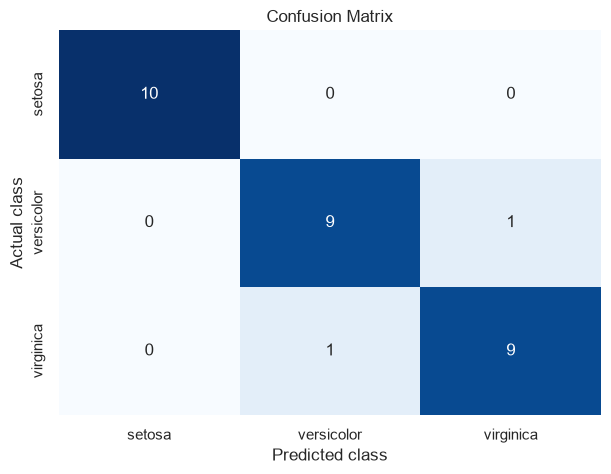

In [12]:
confusion = confusion_matrix(y_test, y_pred, labels=softmax_model.classes_)
confusion_df = pd.DataFrame(
    confusion,
    index=pd.Index(softmax_classes, name="Actual class"),
    columns=pd.Index(softmax_classes, name="Predicted class"),
)

plt.figure(figsize=(7, 5))
sns.heatmap(confusion_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.show()

In [13]:
sample_position = 0
true_class = y_test.iloc[sample_position]
true_class_column = np.where(softmax_model.classes_ == true_class)[0][0]
true_class_probability = y_probability[sample_position, true_class_column]
sample_cross_entropy = -np.log(true_class_probability)

print("True class:", encoder.inverse_transform([true_class])[0])
print(f"Probability assigned to the true class: {true_class_probability:.6f}")
print(f"Per-sample cross-entropy, -log(p_true): {sample_cross_entropy:.6f}")

True class: setosa
Probability assigned to the true class: 0.975641
Per-sample cross-entropy, -log(p_true): 0.024661


## 8. Visualize the Multiclass Decision Regions

Each colored region contains feature combinations for which one class has the highest Softmax probability. The boundaries occur where two classes receive equal highest scores.

> This plot shows only the two-feature model. A four-feature decision surface cannot be displayed directly on a two-dimensional graph.

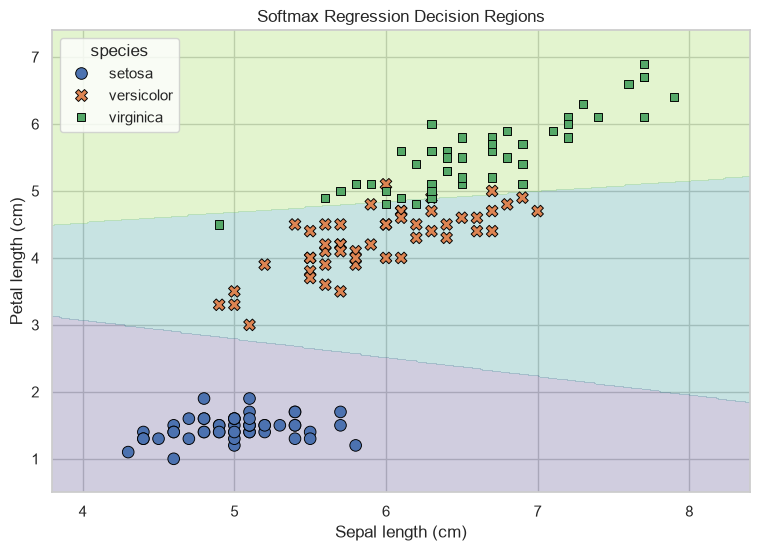

In [14]:
sepal_min, sepal_max = X["sepal_length"].min() - 0.5, X["sepal_length"].max() + 0.5
petal_min, petal_max = X["petal_length"].min() - 0.5, X["petal_length"].max() + 0.5

sepal_grid, petal_grid = np.meshgrid(
    np.linspace(sepal_min, sepal_max, 400),
    np.linspace(petal_min, petal_max, 400),
)
grid = pd.DataFrame(
    {
        "sepal_length": sepal_grid.ravel(),
        "petal_length": petal_grid.ravel(),
    }
)
region_predictions = softmax_model.predict(grid).reshape(sepal_grid.shape)

plt.figure(figsize=(9, 6))
plt.contourf(
    sepal_grid,
    petal_grid,
    region_predictions,
    alpha=0.25,
    levels=np.arange(len(softmax_classes) + 1) - 0.5,
    cmap="viridis",
)
sns.scatterplot(
    data=raw_df,
    x="sepal_length",
    y="petal_length",
    hue="species",
    style="species",
    s=70,
    edgecolor="black",
)
plt.xlim(sepal_min, sepal_max)
plt.ylim(petal_min, petal_max)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Petal length (cm)")
plt.title("Softmax Regression Decision Regions")
plt.show()

## 9. Predict a New Observation

A `DataFrame` makes the feature names and their required order explicit. The probability columns follow `softmax_model.classes_`, so they are labeled with the decoded species names below.

In [15]:
new_flower = pd.DataFrame(
    {
        "sepal_length": [5.8],
        "petal_length": [4.1],
    }
)

new_probabilities = softmax_model.predict_proba(new_flower)
new_encoded_prediction = softmax_model.predict(new_flower)
new_species_prediction = encoder.inverse_transform(new_encoded_prediction)

probability_table = pd.DataFrame(new_probabilities, columns=softmax_classes)
display(new_flower)
display(probability_table.round(6))
print("Predicted encoded class:", new_encoded_prediction[0])
print("Predicted species:", new_species_prediction[0])

,sepal_length,petal_length
0,5.8,4.1


,setosa,versicolor,virginica
0,0.018153,0.911456,0.070391


Predicted encoded class: 1
Predicted species: versicolor


## 10. Compare with a Model That Uses All Four Features

The two-feature model is easy to visualize, but it discards sepal width and petal width. The next model uses all four measurements.

A `Pipeline` fits `StandardScaler` only on the training data and then applies the same transformation to test data. Scaling places the features on comparable scales and can improve numerical optimization.

In [16]:
X_all = raw_df.drop(columns="species")
y_all = raw_df["species"]

X_all_train, X_all_test, y_all_train, y_all_test = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=2,
    stratify=y_all,
)

all_features_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=500),
)
all_features_model.fit(X_all_train, y_all_train)

model_comparison = pd.DataFrame(
    {
        "training_accuracy": [
            train_accuracy,
            all_features_model.score(X_all_train, y_all_train),
        ],
        "testing_accuracy": [
            test_accuracy,
            all_features_model.score(X_all_test, y_all_test),
        ],
    },
    index=["Two features", "All four features"],
)

model_comparison.round(4)

,training_accuracy,testing_accuracy
Two features,0.9667,0.9333
All four features,0.9667,1.0000


In [17]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
cv_results = cross_validate(
    all_features_model,
    X_all,
    y_all,
    cv=cross_validation,
    scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"},
)

cv_summary = pd.DataFrame(
    {
        "fold": np.arange(1, 6),
        "accuracy": cv_results["test_accuracy"],
        "categorical_cross_entropy": -cv_results["test_neg_log_loss"],
    }
)

display(cv_summary.round(4))
print(f"Mean cross-validation accuracy: {cv_summary['accuracy'].mean():.4f}")
print(
    "Mean cross-validation categorical cross-entropy: "
    f"{cv_summary['categorical_cross_entropy'].mean():.4f}"
)

,fold,accuracy,categorical_cross_entropy
0,1,0.9000,0.2019
1,2,0.9667,0.1477
2,3,1.0000,0.0836
3,4,0.9667,0.1770
4,5,0.9333,0.1516


Mean cross-validation accuracy: 0.9533
Mean cross-validation categorical cross-entropy: 0.1523


## Key Takeaways

- **Multinomial Logistic Regression** learns one linear score, or logit, for every class.
- **Softmax** converts the logits into probabilities that sum to one.
- `predict()` selects the class with the largest probability, while `predict_proba()` returns all class probabilities.
- **Categorical cross-entropy** penalizes low probability assigned to the true class.
- A stratified split preserves class proportions, and cross-validation provides a more reliable performance estimate than one split.
- Two features make the model easy to visualize; all four Iris features retain more predictive information.
- Feature scaling should be learned from training data only, which a scikit-learn `Pipeline` handles safely.